# EDA completo — Customer Support Ticket Dataset

**TP2 — Análise Exploratória de Dados**

Este notebook implementa as oito etapas solicitadas no TP2, cobrindo variáveis numéricas, categóricas e textuais, análise multivariada, detecção de anomalias e dois testes formais de hipótese com SciPy. A análise evita expor `Customer Name` e `Customer Email`, pois são identificadores pessoais e não agregam valor ao EDA.

Pergunta orientadora: **o que os tickets revelam sobre o perfil da demanda de suporte e quais sinais são úteis para a futura classificação de intenção a partir do texto do cliente?**

In [1]:
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', palette='deep')

# Funciona com o kernel iniciado na raiz do repositório ou dentro de eda/.
candidates = [Path('../data/customer_support_tickets.csv'), Path('data/customer_support_tickets.csv')]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('customer_support_tickets.csv não encontrado em ../data ou data/.')

df_raw = pd.read_csv(DATA_PATH)
print(f'Arquivo: {DATA_PATH.resolve()}')
print(f'Dimensões: {df_raw.shape[0]:,} linhas × {df_raw.shape[1]} colunas')

Arquivo: D:\_infnet\26E3_26E4\Projeto_de_bloco\_codigo\anderson_breno_francisco\data\customer_support_tickets.csv
Dimensões: 8,469 linhas × 17 colunas


## 1.1. Compreensão do problema e do dataset

Cada linha representa um ticket de suporte. O conjunto combina perfil do cliente, produto, tipo/assunto do contato, texto livre, estado operacional e, para parte dos chamados, informações de resolução e satisfação.

Grupos de variáveis:

- **Identificador:** `Ticket ID` (chave; não será tratado como medida numérica).
- **Numéricas:** `Customer Age` e `Customer Satisfaction Rating`.
- **Categóricas:** gênero, produto, tipo, assunto, status, prioridade e canal.
- **Textuais:** `Ticket Description` e `Resolution`. Nome e e-mail são identificadores/PII, não atributos semânticos para análise.
- **Temporais:** data de compra, horário da primeira resposta e horário de resolução.

Do ponto de vista de negócio, interessa compreender volume e composição dos contatos, satisfação e qualidade dos campos que podem alimentar uma futura classificação de intenção. Não se assume causalidade: o EDA identifica associações e problemas de qualidade.

In [2]:
data_dictionary = pd.DataFrame({
    'grupo': [
        'ID', 'PII', 'PII', 'numérica', 'categórica', 'categórica', 'temporal',
        'categórica', 'categórica', 'texto', 'categórica', 'texto', 'categórica',
        'categórica', 'temporal', 'temporal', 'numérica/ordinal'
    ]
}, index=df_raw.columns)
data_dictionary

,grupo
Ticket ID,ID
Customer Name,PII
Customer Email,PII
Customer Age,numérica
Customer Gender,categórica
Product Purchased,categórica
Date of Purchase,temporal
Ticket Type,categórica
Ticket Subject,categórica
Ticket Description,texto


## 1.2. Inspeção inicial

In [3]:
print('Tipos originais:')
display(df_raw.dtypes.to_frame('dtype'))
print('Amostra sem nome/e-mail:')
display(df_raw.drop(columns=['Customer Name', 'Customer Email']).head(5))

Tipos originais:


,dtype
Ticket ID,int64
Customer Name,object
Customer Email,object
Customer Age,int64
Customer Gender,object
Product Purchased,object
Date of Purchase,object
Ticket Type,object
Ticket Subject,object
Ticket Description,object


Amostra sem nome/e-mail:


,Ticket ID,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [4]:
numeric_original = ['Customer Age', 'Customer Satisfaction Rating']
categorical_cols = [
    'Customer Gender', 'Product Purchased', 'Ticket Type', 'Ticket Subject',
    'Ticket Status', 'Ticket Priority', 'Ticket Channel'
]
text_cols = ['Ticket Description', 'Resolution']

print('Resumo das variáveis numéricas:')
display(df_raw[numeric_original].describe().T)

cardinality = pd.DataFrame({
    'n_unicos': df_raw[categorical_cols + text_cols].nunique(dropna=True),
    'pct_unicos': 100 * df_raw[categorical_cols + text_cols].nunique(dropna=True) / len(df_raw)
})
print('Cardinalidade de categóricas e textos:')
display(cardinality.round(2))

Resumo das variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max
Customer Age,8469.0,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Satisfaction Rating,2769.0,2.991333,1.407016,1.0,2.0,3.0,4.0,5.0


Cardinalidade de categóricas e textos:


,n_unicos,pct_unicos
Customer Gender,3,0.04
Product Purchased,42,0.50
Ticket Type,5,0.06
Ticket Subject,16,0.19
Ticket Status,3,0.04
Ticket Priority,4,0.05
Ticket Channel,4,0.05
Ticket Description,8077,95.37
Resolution,2769,32.70


### Leitura inicial

`Ticket ID` é apenas identificador. A satisfação é ordinal (1 a 5) e está disponível somente para uma parcela dos registros. `Ticket Description` possui alta cardinalidade e será analisado por tamanho e tokens; `Resolution` só faz sentido nos tickets encerrados. Os três campos temporais chegam como texto e precisam ser convertidos antes de qualquer checagem cronológica.

## 1.3. Verificação da qualidade dos dados

São verificados valores ausentes, duplicidades, unicidade da chave, domínios esperados e consistência da ausência de campos de encerramento com o status do ticket.

In [5]:
quality = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'nulos': df_raw.isna().sum(),
    'pct_nulos': (100 * df_raw.isna().mean()).round(2),
    'n_unicos': df_raw.nunique(dropna=True)
})
display(quality)

print(f'Linhas exatamente duplicadas: {df_raw.duplicated().sum()}')
print(f'Ticket ID duplicados: {df_raw["Ticket ID"].duplicated().sum()}')
print(f'IDs ausentes: {df_raw["Ticket ID"].isna().sum()}')
print(f'Idades fora de 18–100: {(~df_raw["Customer Age"].between(18, 100)).sum()}')
rating_invalid = df_raw['Customer Satisfaction Rating'].dropna().loc[lambda s: ~s.between(1, 5)]
print(f'Avaliações fora de 1–5: {len(rating_invalid)}')

,dtype,nulos,pct_nulos,n_unicos
Ticket ID,int64,0,0.00,8469
Customer Name,object,0,0.00,8028
Customer Email,object,0,0.00,8320
Customer Age,int64,0,0.00,53
Customer Gender,object,0,0.00,3
Product Purchased,object,0,0.00,42
Date of Purchase,object,0,0.00,730
Ticket Type,object,0,0.00,5
Ticket Subject,object,0,0.00,16
Ticket Description,object,0,0.00,8077


Linhas exatamente duplicadas: 0
Ticket ID duplicados: 0
IDs ausentes: 0
Idades fora de 18–100: 0
Avaliações fora de 1–5: 0


,First Response Time,Time to Resolution,Resolution,Customer Satisfaction Rating
Status,,,,
Closed,0.0,0.0,0.0,0.0
Open,100.0,100.0,100.0,100.0
Pending Customer Response,0.0,100.0,100.0,100.0


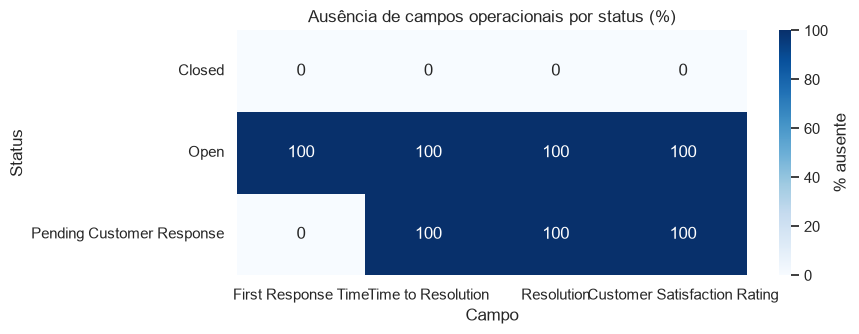

In [6]:
closure_cols = ['First Response Time', 'Time to Resolution', 'Resolution', 'Customer Satisfaction Rating']
missing_by_status = df_raw.groupby('Ticket Status')[closure_cols].agg(lambda s: s.isna().mean() * 100)
display(missing_by_status.round(1).rename_axis('Status'))

plt.figure(figsize=(9, 3.5))
sns.heatmap(missing_by_status, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar_kws={'label': '% ausente'})
plt.title('Ausência de campos operacionais por status (%)')
plt.xlabel('Campo')
plt.ylabel('Status')
plt.tight_layout()
plt.show()

### Qualidade: interpretação

Não há duplicidade de linhas nem de `Ticket ID`, e os domínios de idade e satisfação estão dentro dos intervalos esperados. Os nulos não são aleatórios: `Time to Resolution`, `Resolution` e `Customer Satisfaction Rating` faltam em **100% dos tickets Open e Pending** e existem em **100% dos Closed**; `First Response Time` falta em todos os Open, mas existe em Closed e Pending. Portanto, imputar esses valores misturaria estados operacionais diferentes e introduziria informação artificial.

## 1.4. Limpeza e preparação dos dados

A preparação é feita em uma cópia para preservar os dados brutos. Datas são convertidas com `errors='coerce'`, textos/categorias têm espaços externos removidos e são criadas apenas variáveis derivadas úteis ao EDA. Valores ausentes estruturais **não são imputados**.

In [7]:
df = df_raw.copy()

for col in categorical_cols + text_cols:
    df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

date_cols = ['Date of Purchase', 'First Response Time', 'Time to Resolution']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

df['Description Characters'] = df['Ticket Description'].str.len()
df['Description Words'] = df['Ticket Description'].str.split().str.len()
df['Resolution Characters'] = df['Resolution'].str.len()

product_info_subjects = {
    'Product compatibility', 'Peripheral compatibility',
    'Product setup', 'Installation support'
}
df['Product-info subject'] = df['Ticket Subject'].isin(product_info_subjects)
df['Social media channel'] = df['Ticket Channel'].eq('Social media')
df['Resolution minus first response (h)'] = (
    df['Time to Resolution'] - df['First Response Time']
).dt.total_seconds() / 3600

print('Falhas de conversão adicionais nas datas (além dos nulos originais):')
for col in date_cols:
    introduced = df[col].isna().sum() - df_raw[col].isna().sum()
    print(f'- {col}: {introduced}')

display(df[['Date of Purchase', 'First Response Time', 'Time to Resolution',
            'Description Characters', 'Description Words']].head())

Falhas de conversão adicionais nas datas (além dos nulos originais):
- Date of Purchase: 0
- First Response Time: 0
- Time to Resolution: 0


,Date of Purchase,First Response Time,Time to Resolution,Description Characters,Description Words
0,2021-03-22,2023-06-01 12:15:36,NaT,290,43
1,2021-05-22,2023-06-01 16:45:38,NaT,288,44
2,2020-07-14,2023-06-01 11:14:38,2023-06-01 18:05:38,277,42
3,2020-11-13,2023-06-01 07:29:40,2023-06-01 01:57:40,264,41
4,2020-02-04,2023-06-01 00:12:42,2023-06-01 19:53:42,336,55


## 1.5. Análise Univariada

### Variáveis numéricas

Idade, satisfação e medidas de tamanho do texto são examinadas por estatísticas descritivas e histogramas. A satisfação é tratada como ordinal; média é apresentada apenas como resumo complementar.

,count,mean,std,min,25%,50%,75%,max
Customer Age,8469.0,44.03,15.30,18.0,31.0,44.0,57.0,70.0
Customer Satisfaction Rating,2769.0,2.99,1.41,1.0,2.0,3.0,4.0,5.0
Description Characters,8469.0,292.34,43.54,151.0,276.0,301.0,321.0,397.0
Description Words,8469.0,46.47,8.46,21.0,43.0,49.0,52.0,63.0


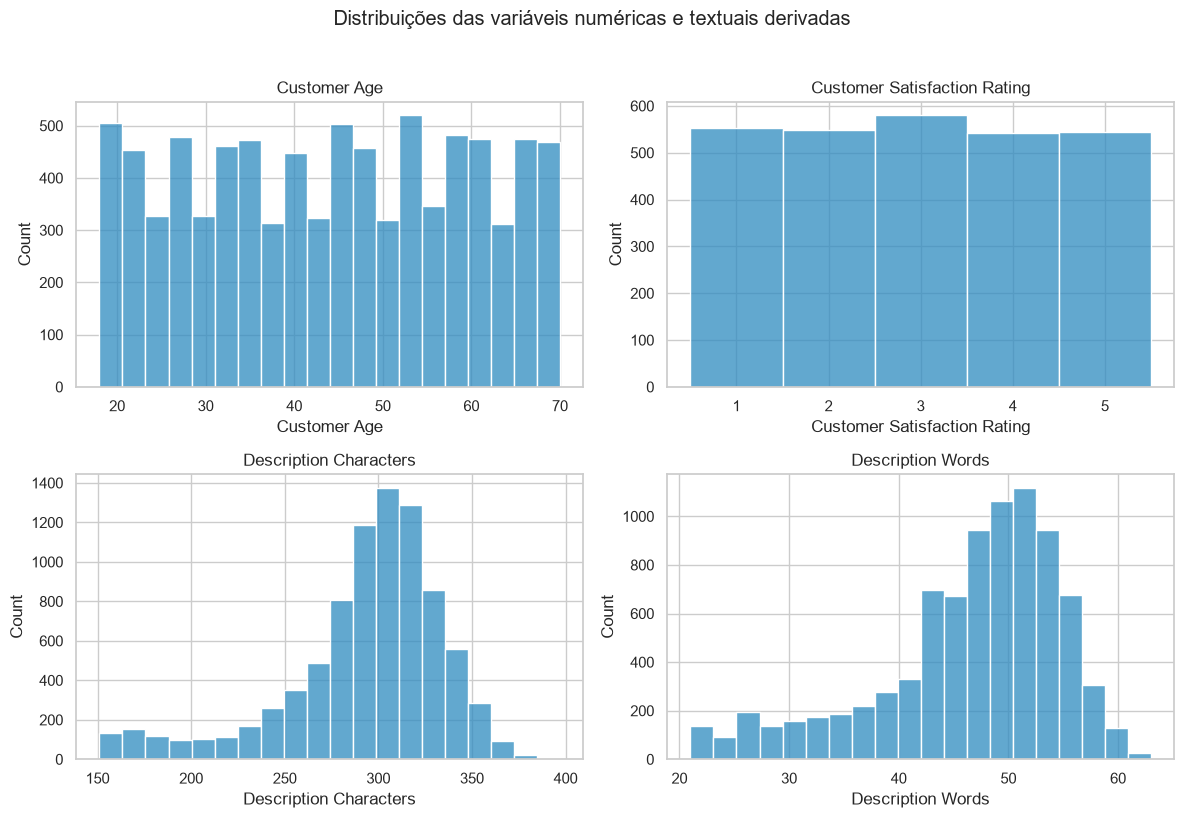

In [8]:
numeric_eda = ['Customer Age', 'Customer Satisfaction Rating', 'Description Characters', 'Description Words']
display(df[numeric_eda].describe().T.round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, numeric_eda):
    bins = np.arange(0.5, 6.5, 1) if col == 'Customer Satisfaction Rating' else 20
    sns.histplot(df[col].dropna(), bins=bins, ax=ax, color='#2E8BC0')
    ax.set_title(col)
plt.suptitle('Distribuições das variáveis numéricas e textuais derivadas', y=1.02)
plt.tight_layout()
plt.show()

### Variáveis categóricas


Ticket Type


,n,%
Ticket Type,,
Refund request,1752,20.69
Technical issue,1747,20.63
Cancellation request,1695,20.01
Product inquiry,1641,19.38
Billing inquiry,1634,19.29



Ticket Status


,n,%
Ticket Status,,
Pending Customer Response,2881,34.02
Open,2819,33.29
Closed,2769,32.70



Ticket Priority


,n,%
Ticket Priority,,
Medium,2192,25.88
Critical,2129,25.14
High,2085,24.62
Low,2063,24.36



Ticket Channel


,n,%
Ticket Channel,,
Email,2143,25.30
Phone,2132,25.17
Social media,2121,25.04
Chat,2073,24.48



Customer Gender


,n,%
Customer Gender,,
Male,2896,34.20
Female,2887,34.09
Other,2686,31.72


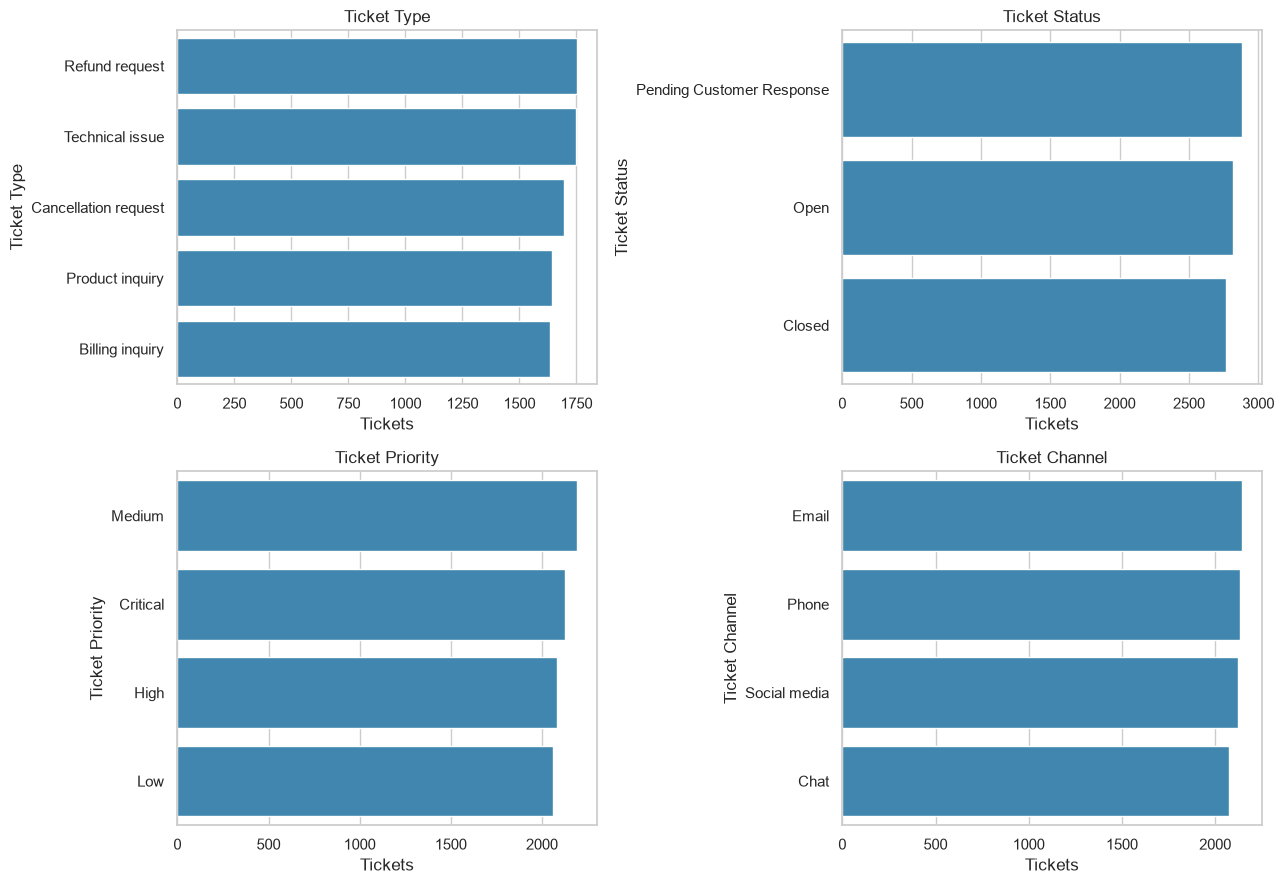

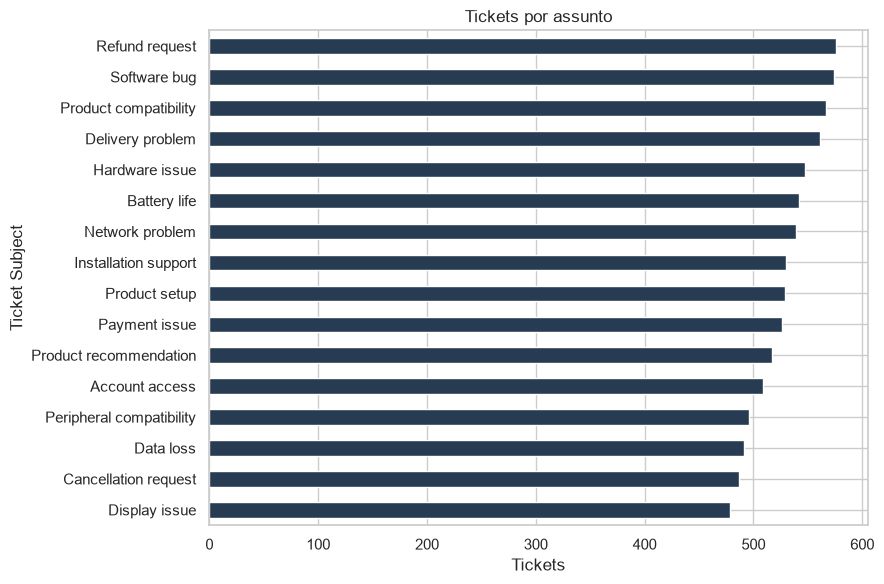

In [9]:
for col in ['Ticket Type', 'Ticket Status', 'Ticket Priority', 'Ticket Channel', 'Customer Gender']:
    freq = df[col].value_counts().to_frame('n')
    freq['%'] = (100 * freq['n'] / len(df)).round(2)
    print(f'\n{col}')
    display(freq)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ['Ticket Type', 'Ticket Status', 'Ticket Priority', 'Ticket Channel']):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color='#2E8BC0')
    ax.set_title(col)
    ax.set_xlabel('Tickets')
plt.tight_layout()
plt.show()

subject_counts = df['Ticket Subject'].value_counts().sort_values()
plt.figure(figsize=(9, 6))
subject_counts.plot.barh(color='#273C52')
plt.title('Tickets por assunto')
plt.xlabel('Tickets')
plt.tight_layout()
plt.show()

### Variáveis textuais

Além do tamanho das descrições, são observados os tokens mais frequentes. A contagem exclui uma pequena lista de stopwords e termos do boilerplate do dataset; seu objetivo é diagnóstico exploratório, não preparação final de NLP. `Resolution` não entra na análise lexical porque é um campo posterior ao atendimento e está ausente fora dos chamados fechados.

,token,frequência
0,i'm,10294
1,i've,6002
2,problem,2285
3,any,2048
4,there,1676
5,data,1668
6,what,1575
7,software,1555
8,account,1464
9,steps,1390


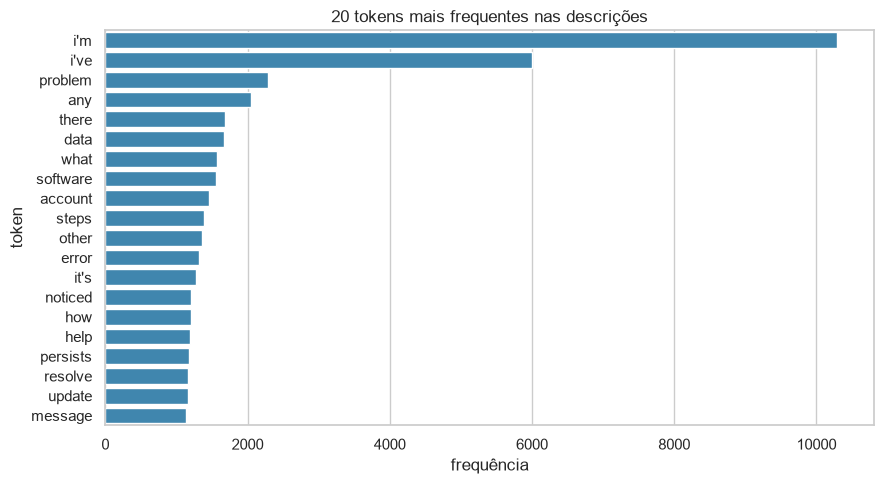

In [10]:
stopwords = {
    'the','a','an','and','or','to','of','in','on','for','with','is','it','this','that','i','my','me',
    'im','ive','but','be','as','are','was','have','has','had','not','please','having','issue','assist',
    'product','purchased','your','you','its','at','so','do','does','did','can','could','would','when'
}
tokens = []
for text in df['Ticket Description'].dropna().str.lower():
    tokens.extend(w for w in re.findall(r"[a-z']{3,}", text) if w not in stopwords)
top_tokens = pd.DataFrame(Counter(tokens).most_common(20), columns=['token', 'frequência'])
display(top_tokens)

plt.figure(figsize=(9, 5))
sns.barplot(data=top_tokens, x='frequência', y='token', color='#2E8BC0')
plt.title('20 tokens mais frequentes nas descrições')
plt.tight_layout()
plt.show()

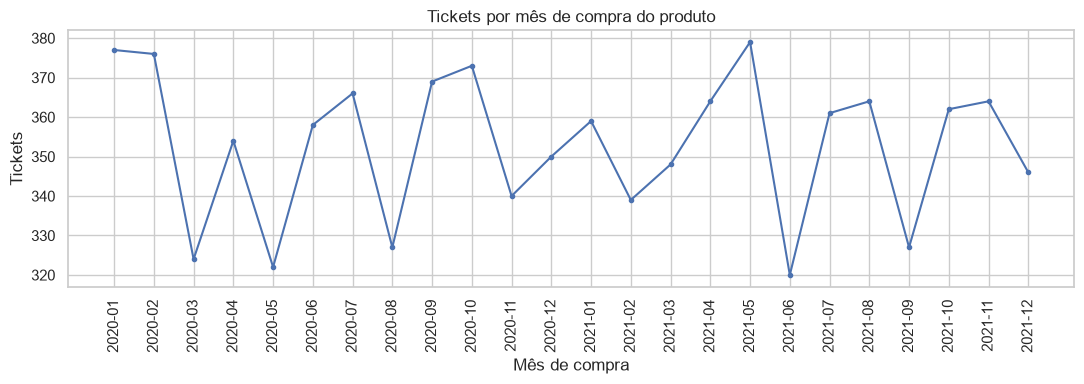

In [11]:
purchase_month = df['Date of Purchase'].dt.to_period('M').value_counts().sort_index()
plt.figure(figsize=(11, 4))
plt.plot(purchase_month.index.astype(str), purchase_month.values, marker='o', markersize=3)
plt.xticks(rotation=90)
plt.title('Tickets por mês de compra do produto')
plt.ylabel('Tickets')
plt.xlabel('Mês de compra')
plt.tight_layout()
plt.show()

### Síntese univariada

As principais categorias são relativamente equilibradas: os cinco tipos de ticket ficam próximos de 20% cada; status, prioridade, canal e gênero também não apresentam uma categoria dominante. A idade cobre de 18 a 70 anos. A satisfação dos 2.769 tickets fechados cobre toda a escala 1–5 e tem mediana 3. As descrições são curtas/moderadas e contêm muito texto-modelo, sinal importante para a futura etapa de NLP.

## 1.6. Análise Multivariada

A análise combina correlações numéricas/ordinais, relações entre categóricas e satisfação por grupos. Como satisfação é ordinal e os tamanhos de texto são assimétricos, a matriz usa **correlação de Spearman**.

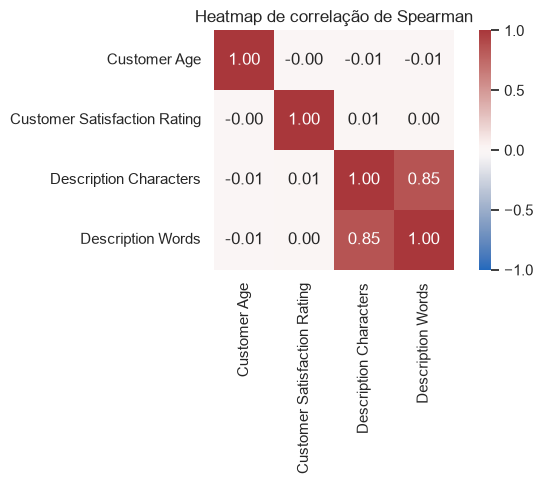

,Customer Age,Customer Satisfaction Rating,Description Characters,Description Words
Customer Age,1.000,-0.004,-0.014,-0.011
Customer Satisfaction Rating,-0.004,1.000,0.005,0.004
Description Characters,-0.014,0.005,1.000,0.852
Description Words,-0.011,0.004,0.852,1.000


In [12]:
corr_cols = ['Customer Age', 'Customer Satisfaction Rating', 'Description Characters', 'Description Words']
corr = df[corr_cols].corr(method='spearman')
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True)
plt.title('Heatmap de correlação de Spearman')
plt.tight_layout()
plt.show()
display(corr.round(3))

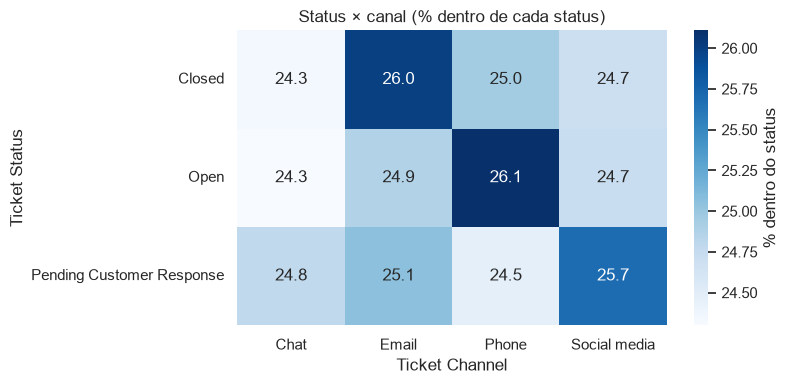

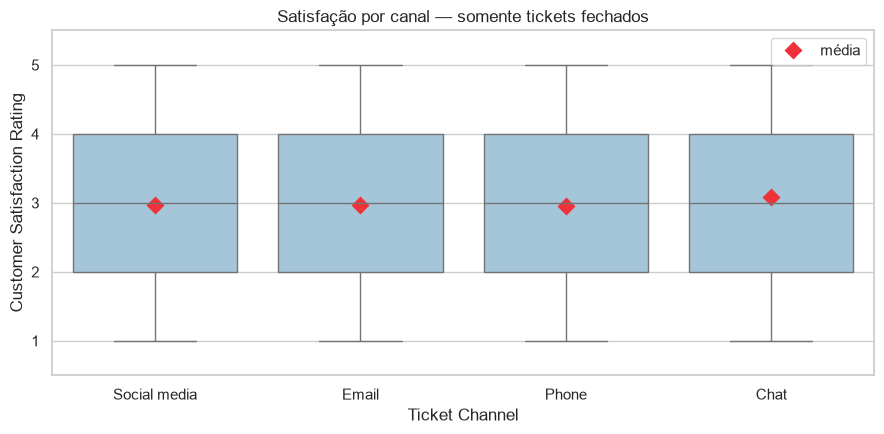

In [13]:
status_channel = pd.crosstab(df['Ticket Status'], df['Ticket Channel'], normalize='index') * 100
plt.figure(figsize=(8, 4))
sns.heatmap(status_channel, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% dentro do status'})
plt.title('Status × canal (% dentro de cada status)')
plt.tight_layout()
plt.show()

closed = df[df['Customer Satisfaction Rating'].notna()].copy()
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=closed, x='Ticket Channel', y='Customer Satisfaction Rating', color='#9CC9E2')
sns.pointplot(data=closed, x='Ticket Channel', y='Customer Satisfaction Rating', color='#EF3139',
              markers='D', linestyles='none', errorbar=None, label='média')
plt.title('Satisfação por canal — somente tickets fechados')
plt.ylim(0.5, 5.5)
plt.tight_layout()
plt.show()

### Hipóteses e testes formais

Os testes operacionalizam duas hipóteses de negócio levantadas no TP1. Como `Customer Satisfaction Rating` é uma escala ordinal de 1 a 5, o **Mann–Whitney U bilateral** é mais apropriado do que o t-test. Nível de significância pré-definido: **α = 0,05**.

#### Hipótese 1 — necessidade de informações sobre produtos

No TP1 observou-se volume relevante de `Product compatibility`, `Peripheral compatibility`, `Product setup` e `Installation support`. Aqui verificamos se esse grupo também apresenta experiência de satisfação diferente.

- **H0:** a distribuição de satisfação dos tickets desses quatro assuntos é igual à dos demais assuntos.
- **H1:** as distribuições de satisfação diferem entre os grupos.

In [14]:
def mann_whitney_report(a, b, label_a, label_b):
    a, b = a.dropna(), b.dropna()
    result = mannwhitneyu(a, b, alternative='two-sided', method='asymptotic')
    rank_biserial = 2 * result.statistic / (len(a) * len(b)) - 1
    summary = pd.DataFrame({
        'grupo': [label_a, label_b], 'n': [len(a), len(b)],
        'média': [a.mean(), b.mean()], 'mediana': [a.median(), b.median()]
    })
    display(summary.round(3))
    print(f'U = {result.statistic:.1f} | p-valor = {result.pvalue:.6f} | r rank-biserial = {rank_biserial:.4f}')
    print('Decisão:', 'rejeitar H0' if result.pvalue < 0.05 else 'não rejeitar H0', '(α = 0,05)')
    return result, rank_biserial

h1_a = closed.loc[closed['Product-info subject'], 'Customer Satisfaction Rating']
h1_b = closed.loc[~closed['Product-info subject'], 'Customer Satisfaction Rating']
h1_result, h1_effect = mann_whitney_report(h1_a, h1_b, 'Assuntos de informação de produto', 'Demais assuntos')

,grupo,n,média,mediana
0,Assuntos de informação de produto,694,3.017,3.0
1,Demais assuntos,2075,2.983,3.0


U = 730150.0 | p-valor = 0.570862 | r rank-biserial = 0.0141
Decisão: não rejeitar H0 (α = 0,05)


**Interpretação H1:** no dataset atual, o teste retorna p ≈ **0,571**, acima de 0,05. Portanto, **não rejeitamos H0**. As medianas são 3 nos dois grupos e o efeito rank-biserial é ≈ **0,014**, praticamente nulo. O volume desses assuntos sustenta que existe demanda por informação/configuração, mas **não há evidência de que essa demanda venha acompanhada de satisfação diferente** nos tickets fechados. Isso é associação, não causalidade.

#### Hipótese 2 — atrito no canal de redes sociais

O TP1 sugeriu que contatos por `Social media` poderiam representar atrito no processo de busca de informação. Um sinal mensurável disponível é a satisfação após fechamento.

- **H0:** a distribuição de satisfação de tickets de Social media é igual à dos demais canais.
- **H1:** as distribuições de satisfação diferem entre Social media e os demais canais.

In [15]:
h2_a = closed.loc[closed['Social media channel'], 'Customer Satisfaction Rating']
h2_b = closed.loc[~closed['Social media channel'], 'Customer Satisfaction Rating']
h2_result, h2_effect = mann_whitney_report(h2_a, h2_b, 'Social media', 'Demais canais')

,grupo,n,média,mediana
0,Social media,684,2.969,3.0
1,Demais canais,2085,2.999,3.0


U = 704763.0 | p-valor = 0.640306 | r rank-biserial = -0.0116
Decisão: não rejeitar H0 (α = 0,05)


**Interpretação H2:** p ≈ **0,640**, também acima de 0,05; **não rejeitamos H0**. A mediana é 3 em ambos os grupos e o efeito rank-biserial é ≈ **−0,012**, praticamente nulo. Portanto, o dataset não fornece evidência de diferença de satisfação associada ao canal Social media. O volume no canal, sozinho, não demonstra atrito.

**Hipótese de descontinuidade do TP1:** a ideia de que `Pending Customer Response` pode refletir latência/desistência permanece apenas como hipótese descritiva. O dataset não possui `Ticket Created Time` e, como será mostrado na seção de anomalias, quase metade dos registros fechados tem ordem temporal impossível entre primeira resposta e resolução. Por isso, não é estatisticamente defensável transformar esses timestamps em tempo de espera para testar descontinuidade.

## 1.7. Identificação de Outliers e Anomalias

Para variáveis quantitativas é aplicada a regra de **1,5 × IQR**. Em paralelo, regras de domínio e coerência temporal são mais importantes para idade/satisfação e timestamps. Outlier não é removido automaticamente: primeiro é diagnosticado.

,Q1,Q3,IQR,limite_inf,limite_sup,n_outliers,pct_outliers
Customer Age,31.0,57.0,26.0,-8.0,96.0,0.0,0.00
Customer Satisfaction Rating,2.0,4.0,2.0,-1.0,7.0,0.0,0.00
Description Characters,276.0,321.0,45.0,208.5,388.5,580.0,6.85
Description Words,43.0,52.0,9.0,29.5,65.5,555.0,6.55


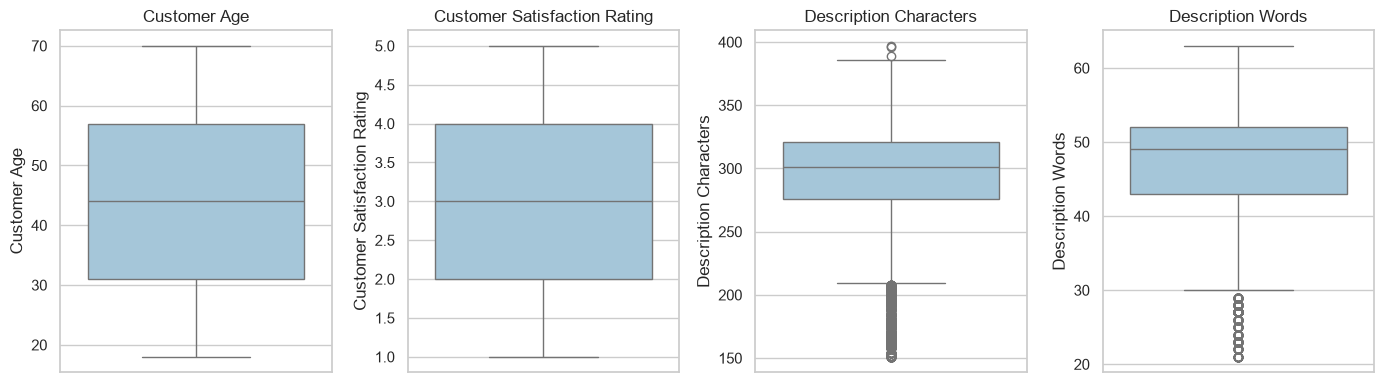

In [16]:
def iqr_summary(series):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (s < low) | (s > high)
    return pd.Series({
        'Q1': q1, 'Q3': q3, 'IQR': iqr, 'limite_inf': low, 'limite_sup': high,
        'n_outliers': is_outlier.sum(), 'pct_outliers': 100 * is_outlier.mean()
    })

outlier_table = pd.DataFrame({col: iqr_summary(df[col]) for col in numeric_eda}).T
display(outlier_table.round(2))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, numeric_eda):
    sns.boxplot(y=df[col], ax=ax, color='#9CC9E2')
    ax.set_title(col)
plt.tight_layout()
plt.show()

Registros com primeira resposta e resolução: 2,769
Resolução anterior à primeira resposta: 1,365 (49.3%)
Resolução exatamente no mesmo instante: 2


,horas
count,2769.00
mean,-0.06
std,9.56
min,-23.23
25%,-6.93
50%,0.17
75%,6.48
max,23.47


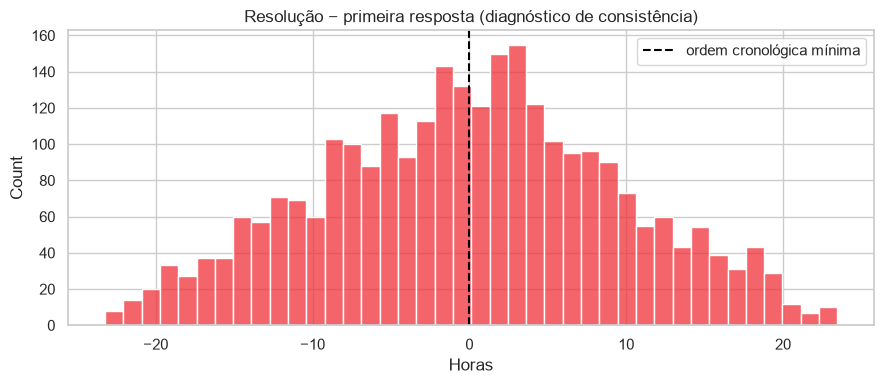

In [17]:
elapsed = df['Resolution minus first response (h)'].dropna()
temporal_anomalies = (elapsed < 0).sum()
print(f'Registros com primeira resposta e resolução: {len(elapsed):,}')
print(f'Resolução anterior à primeira resposta: {temporal_anomalies:,} ({100 * temporal_anomalies / len(elapsed):.1f}%)')
print(f'Resolução exatamente no mesmo instante: {(elapsed == 0).sum():,}')
display(elapsed.describe().to_frame('horas').round(2))

plt.figure(figsize=(9, 4))
sns.histplot(elapsed, bins=40, color='#EF3139')
plt.axvline(0, color='black', linestyle='--', label='ordem cronológica mínima')
plt.title('Resolução − primeira resposta (diagnóstico de consistência)')
plt.xlabel('Horas')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretação dos outliers/anomalias

- **Idade e satisfação:** nenhum outlier pela regra IQR; também não há violação dos domínios observados (18–70 anos e notas 1–5).
- **Comprimento do texto:** existem caudas superiores (descrições especialmente longas), mas isso é plausível em texto livre. Esses registros são mantidos; truncá-los eliminaria informação que pode ser útil no NLP.
- **Timestamps:** esta é a anomalia mais séria. Dos 2.769 tickets com os dois horários, **1.365 (49,3%)** apresentam resolução anterior à primeira resposta. Portanto, `Time to Resolution - First Response Time` **não é uma duração confiável** e não deve ser usada como variável analítica/modelo sem correção na origem.
- **Missingness estrutural:** satisfação e resolução só existem para `Closed`. Qualquer análise dessas variáveis representa o subconjunto encerrado, não todos os tickets.

## 1.8. Documentação do EDA e conclusões

### Problema e dados

O dataset contém **8.469 tickets e 17 colunas**. Ele é adequado para estudar composição da demanda e preparar um problema futuro de classificação de intenção, mas não é adequado, no estado atual, para calcular SLA/tempo de resolução. PII foi deliberadamente excluída das visualizações e exemplos.

### Principais resultados

1. A chave `Ticket ID` é íntegra e não há linhas duplicadas. Idade e satisfação respeitam seus domínios.
2. Os nulos em resolução/satisfação são **estruturais por status**; não devem ser imputados.
3. Tipos de ticket, status, prioridade e canais são relativamente balanceados, sem classe majoritária esmagadora.
4. Os textos têm alta cardinalidade, porém contêm boilerplate repetitivo. Isso pode permitir que um classificador aprenda padrões artificiais; a etapa de ML deverá validar generalização com split apropriado e métricas por classe.
5. O heatmap não mostra correlações monotônicas fortes entre idade, satisfação e tamanho da descrição.
6. **Hipótese 1:** assuntos ligados a informação/configuração de produto não apresentam satisfação diferente dos demais (Mann–Whitney, p≈0,571; efeito≈0,014).
7. **Hipótese 2:** Social media não apresenta satisfação diferente dos demais canais (Mann–Whitney, p≈0,640; efeito≈−0,012).
8. A ordem temporal é inconsistente em 49,3% dos tickets fechados com ambos os horários; durações derivadas desses campos foram descartadas para inferência.

### Conexão com a classificação do TP3

Para o próximo ciclo, a formulação natural é classificar **intenção/tipo do ticket (`Ticket Type`) a partir de `Ticket Description`**. O alvo tem cinco classes aproximadamente equilibradas. `Ticket ID`, nome, e-mail e campos posteriores ao atendimento (`Resolution`, status final, satisfação e timestamps de resolução) devem ficar fora das features para evitar PII, variáveis sem significado preditivo ou *data leakage*. Como próximo passo, recomenda-se baseline de texto com divisão treino/teste estratificada e avaliação por **macro-F1**, matriz de confusão e métricas por classe.

### Limitações e próximos passos

- Obter um timestamp confiável de abertura e corrigir a cronologia de primeira resposta/resolução antes de estudar SLA ou abandono.
- Investigar a origem do boilerplate das descrições antes de treinar modelos de NLP.
- Não generalizar os testes de satisfação a tickets ainda abertos/pendentes, pois essa nota só existe nos fechados.
- Os testes detectam associação entre grupos; não demonstram causa. Não rejeitar H0 também não prova igualdade absoluta, apenas indica ausência de evidência suficiente de diferença neste conjunto.

<!-- TP3 -->
# TP3 — Da análise estatística à fase preditiva

As seções 1.1 a 1.8 acima consolidam a EDA do TP1 e do TP2. A partir daqui o notebook cobre o TP3:

- **Seção 2** — uma regressão linear com alvo numérico derivado do texto, avaliada por R², RMSE, Residual Plot e Q-Q Plot;
- **Seção 3** — a formalização do problema de classificação de intenções, com a distribuição das classes e a justificativa de por que ele é de classificação e não de regressão.

## 2. Regressão linear e análise do modelo

### 2.1. Definição do experimento

**Variável alvo (y):** `Description Words`, a **quantidade de palavras** de `Ticket Description` (criada na seção 1.4). É numérica, discreta, varia de 21 a 63 palavras e é derivada diretamente do mesmo texto que o classificador vai receber, o que torna o experimento útil para entender esse texto.

**Variáveis de entrada (X)**, em dois grupos:

| Grupo | Variáveis | Tratamento |
| --- | --- | --- |
| Metadados do ticket | `Ticket Type`, `Ticket Priority`, `Ticket Channel`, `Customer Gender`, `Product Purchased` | One-hot encoding |
| Metadados do cliente | `Customer Age` | Padronização (z-score) |
| Estrutura do texto | `Placeholder Count` (ocorrências de `{product_purchased}`), `Paragraph Count` (blocos separados por linha em branco), `Sentence Marks` (pontuações `.`, `!` ou `?` que fecham frases) | Padronização (z-score) |

**Variáveis excluídas de propósito:**

- `Description Characters`: número de caracteres é quase uma reescrita do número de palavras. Usá-la daria um R² alto e inútil (vazamento do alvo).
- `Ticket ID`, `Customer Name` e `Customer Email`: identificadores e dados pessoais, sem significado preditivo.
- `Resolution`, `Ticket Status`, `Customer Satisfaction Rating` e os timestamps de resposta: só existem **depois** do atendimento, então não estariam disponíveis no momento da mensagem.

Os atributos estruturais descrevem o **molde** da mensagem (quantas frases e parágrafos ela tem), não contam palavras. Por isso são entradas legítimas.


In [18]:
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error, r2_score,
                             root_mean_squared_error)
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

reg = df.copy()
desc = reg['Ticket Description']
# Atributos estruturais do texto: descrevem o "molde" da mensagem sem contar palavras.
reg['Placeholder Count'] = desc.str.count(r'\{product_purchased\}')
reg['Paragraph Count'] = desc.str.count(r'\r?\n\s*\r?\n') + 1
reg['Sentence Marks'] = desc.str.count(r'[.!?](?:\s|$)')

TARGET = 'Description Words'
CAT_FEATURES = ['Ticket Type', 'Ticket Priority', 'Ticket Channel',
                'Customer Gender', 'Product Purchased']
META_NUM = ['Customer Age']
STRUCT_NUM = ['Placeholder Count', 'Paragraph Count', 'Sentence Marks']
FEATURES = CAT_FEATURES + META_NUM + STRUCT_NUM

print(f'Registros usados: {len(reg):,} | nulos no alvo: {reg[TARGET].isna().sum()}')
display(reg[[TARGET] + META_NUM + STRUCT_NUM].describe().T.round(2))
display(
    reg[[TARGET] + META_NUM + STRUCT_NUM].corr()[TARGET].drop(TARGET)
    .round(3).to_frame('Pearson r com o alvo')
)

Registros usados: 8,469 | nulos no alvo: 0


,count,mean,std,min,25%,50%,75%,max
Description Words,8469.0,46.47,8.46,21.0,43.0,49.0,52.0,63.0
Customer Age,8469.0,44.03,15.30,18.0,31.0,44.0,57.0,70.0
Placeholder Count,8469.0,1.64,0.58,1.0,1.0,2.0,2.0,5.0
Paragraph Count,8469.0,2.21,1.16,1.0,1.0,2.0,3.0,12.0
Sentence Marks,8469.0,4.61,1.16,2.0,4.0,4.0,5.0,14.0


,Pearson r com o alvo
Customer Age,-0.005
Placeholder Count,0.075
Paragraph Count,-0.074
Sentence Marks,0.330


### 2.2. Treinamento

- Divisão **80% treino / 20% teste**, estratificada por `Ticket Type` e com `random_state=42` (reprodutível).
- Pipeline do scikit-learn: `OneHotEncoder` para as categóricas, `StandardScaler` para as numéricas e `LinearRegression` (mínimos quadrados ordinários). O pré-processamento é ajustado **só no treino**, então o teste não vaza para o modelo.
- Três modelos comparados:
  1. **Baseline**: prevê sempre a média do treino. Serve de piso: um modelo útil precisa ter RMSE menor que ele.
  2. **Modelo A**: só metadados. Testa se o *tipo de pedido*, a prioridade, o canal, o produto ou o perfil do cliente explicam o tamanho da mensagem.
  3. **Modelo B**: metadados + estrutura do texto. É o modelo analisado em detalhe.
- Além do conjunto de teste, o R² também é estimado por **validação cruzada de 5 folds** no treino, para mostrar a estabilidade do resultado.


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    reg[FEATURES], reg[TARGET], test_size=0.2,
    random_state=RANDOM_STATE, stratify=reg['Ticket Type'],
)


def linear_model(num_features):
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
        ('num', StandardScaler(), num_features),
    ])
    return Pipeline([('pre', pre), ('model', LinearRegression())])


models = {
    'Baseline: média do treino': DummyRegressor(strategy='mean'),
    'Modelo A: só metadados': linear_model(META_NUM),
    'Modelo B: metadados + estrutura do texto': linear_model(META_NUM + STRUCT_NUM),
}

rows = []
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    model.fit(X_train, y_train)
    pred_tr, pred_te = model.predict(X_train), model.predict(X_test)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2')
    rows.append({
        'Modelo': name,
        'R² treino': r2_score(y_train, pred_tr),
        'R² teste': r2_score(y_test, pred_te),
        'R² CV (5 folds)': f'{cv_r2.mean():.3f} ± {cv_r2.std():.3f}',
        'RMSE teste (palavras)': root_mean_squared_error(y_test, pred_te),
        'MAE teste (palavras)': mean_absolute_error(y_test, pred_te),
    })

metrics = pd.DataFrame(rows).set_index('Modelo')
display(metrics.round(3))
print(f'Desvio-padrão do alvo no teste: {y_test.std():.2f} palavras')

,R² treino,R² teste,R² CV (5 folds),RMSE teste (palavras),MAE teste (palavras)
Modelo,,,,,
Baseline: média do treino,0.000,-0.000,-0.001 ± 0.001,8.448,6.624
Modelo A: só metadados,0.011,-0.010,-0.008 ± 0.007,8.488,6.630
Modelo B: metadados + estrutura do texto,0.126,0.123,0.109 ± 0.015,7.913,6.247


Desvio-padrão do alvo no teste: 8.45 palavras


In [20]:
best = models['Modelo B: metadados + estrutura do texto']
names = best.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(best.named_steps['model'].coef_, index=names)
num_coefs = coefs[[f'num__{c}' for c in META_NUM + STRUCT_NUM]]
num_coefs.index = num_coefs.index.str.replace('num__', '')
display(num_coefs.round(2).to_frame('Coeficiente (palavras por 1 desvio-padrão)'))

cat_coefs = coefs[coefs.index.str.startswith('cat__')]
print(f'Amplitude dos {len(cat_coefs)} coeficientes categóricos: '
      f'{cat_coefs.min():.2f} a {cat_coefs.max():.2f} palavras')

,Coeficiente (palavras por 1 desvio-padrão)
Customer Age,-0.10
Placeholder Count,0.15
Paragraph Count,-0.81
Sentence Marks,2.82


Amplitude dos 58 coeficientes categóricos: -1.58 a 2.51 palavras


### 2.3. Resultados: R² e RMSE

**O que as métricas medem:**

- **R²** é a fração da variância do alvo que o modelo explica. Com R² = 0 o modelo é tão bom quanto prever sempre a média, e com R² = 1 ele acerta tudo. Valores negativos indicam um modelo **pior** que a média.
- **RMSE** (raiz do erro quadrático médio) é o erro típico na mesma unidade do alvo, aqui **palavras**. Por elevar os erros ao quadrado, pesa mais os erros grandes. O MAE (erro absoluto médio) foi incluído como apoio, porque é menos sensível a esses extremos.

**Leitura dos resultados no conjunto de teste:**

| Modelo | R² teste | RMSE teste | Leitura |
| --- | ---: | ---: | --- |
| Baseline (média) | 0,000 | 8,45 | Piso de referência: o RMSE coincide com o desvio-padrão do alvo (8,45). |
| A: só metadados | −0,010 | 8,49 | **Pior que a média.** Tipo de pedido, prioridade, canal, produto, gênero e idade não explicam nada do tamanho da mensagem. O pequeno ganho no treino (R² 0,011) é ajuste a ruído (*overfitting*). |
| B: + estrutura do texto | **0,123** | **7,91** | Explica cerca de **12%** da variância. O erro típico cai de 8,45 para 7,91 palavras (−6%), mas o modelo ainda erra cerca de 8 palavras numa mensagem de ~46. |

- R² no treino (0,126), no teste (0,123) e na validação cruzada (0,109 ± 0,015) são próximos. O Modelo B **não está sobreajustado**, apenas explica pouco. É um caso de *underfitting*: falta informação nas entradas, e não sobra complexidade no modelo.
- Quase todo o poder explicativo vem de `Sentence Marks` (+2,8 palavras por desvio-padrão; r = 0,33 com o alvo). É o resultado esperado, já que mensagens com mais frases tendem a ter mais palavras. `Paragraph Count` tem sinal negativo (−0,8) quando a quantidade de frases é mantida constante: o mesmo número de frases distribuído em mais parágrafos indica blocos curtos.
- O resultado do Modelo A **confirma a EDA da seção 1.6**: o heatmap já mostrava correlação praticamente nula entre o tamanho da descrição e as demais variáveis. **Nenhuma categoria de ticket produz mensagens sistematicamente maiores ou menores.**


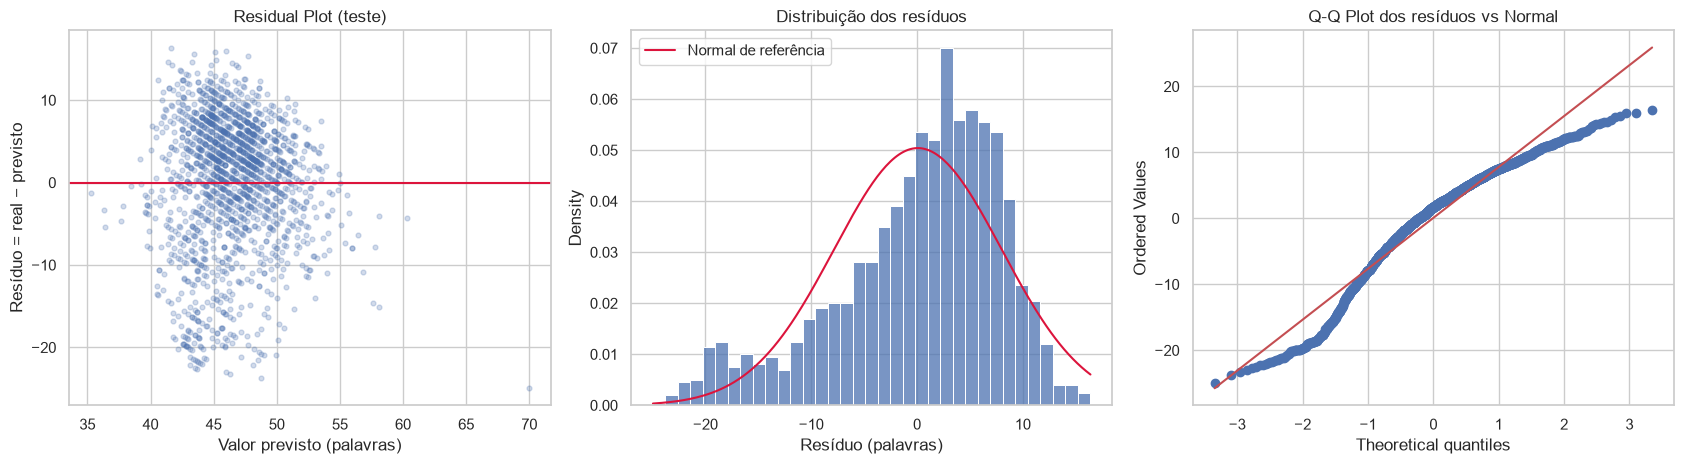

,Valor
Média dos resíduos,0.0773
Assimetria (skew),-0.8241
Curtose (excesso),0.2629
p-valor D'Agostino-Pearson (normalidade),0.0000
Spearman |resíduo| × previsto,-0.2238
p-valor Spearman,0.0000
% de resíduos com |r| > 10 palavras,18.0047


In [21]:
pred_test = best.predict(X_test)
residuals = y_test - pred_test

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].scatter(pred_test, residuals, alpha=0.25, s=12)
axes[0].axhline(0, color='crimson', lw=1.5)
axes[0].set(title='Residual Plot (teste)', xlabel='Valor previsto (palavras)',
            ylabel='Resíduo = real − previsto')

sns.histplot(residuals, bins=35, stat='density', ax=axes[1])
grid = np.linspace(residuals.min(), residuals.max(), 200)
axes[1].plot(grid, stats.norm.pdf(grid, residuals.mean(), residuals.std()), color='crimson',
             label='Normal de referência')
axes[1].set(title='Distribuição dos resíduos', xlabel='Resíduo (palavras)')
axes[1].legend()

stats.probplot(residuals, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot dos resíduos vs Normal')

plt.tight_layout()
plt.show()

_, normal_p = stats.normaltest(residuals)
spearman_het = stats.spearmanr(pred_test, residuals.abs())
summary = pd.Series({
    'Média dos resíduos': residuals.mean(),
    'Assimetria (skew)': stats.skew(residuals),
    'Curtose (excesso)': stats.kurtosis(residuals),
    "p-valor D'Agostino-Pearson (normalidade)": normal_p,
    'Spearman |resíduo| × previsto': spearman_het.statistic,
    'p-valor Spearman': spearman_het.pvalue,
    '% de resíduos com |r| > 10 palavras': (residuals.abs() > 10).mean() * 100,
})
display(summary.round(4).to_frame('Valor'))

### 2.4. Análise dos resíduos (Residual Plot e Q-Q Plot)

A regressão linear por mínimos quadrados supõe resíduos com média zero, **variância constante** (homocedasticidade), **sem padrão** em relação ao valor previsto e, para os intervalos de confiança e testes sobre os coeficientes, **distribuição aproximadamente normal**. Os gráficos acima mostram que essas hipóteses não se sustentam:

- **Residual Plot:** os pontos não formam uma nuvem aleatória em torno de zero. Aparecem **faixas diagonais paralelas**, consequência de o alvo ser uma **contagem inteira**: para cada valor real fixo, o resíduo cai em linha reta conforme a previsão aumenta. Além disso, as previsões ficam espremidas entre ~40 e ~55 palavras, enquanto o alvo vai de 21 a 63. O modelo puxa tudo para perto da média e não consegue prever mensagens muito curtas.
- **Heterocedasticidade:** a correlação de Spearman entre |resíduo| e valor previsto é −0,22 (p < 0,001). Os erros são **maiores quando o modelo prevê mensagens curtas**, ou seja, a variância não é constante.
- **Histograma e Q-Q Plot:** a distribuição dos resíduos é **assimétrica à esquerda** (skew = −0,82), com uma cauda longa de resíduos entre −15 e −25 palavras. No Q-Q Plot, os pontos da cauda esquerda ficam abaixo da reta, porque há mais erros negativos grandes do que a Normal prevê, e a cauda direita se achata em ~+16, porque o alvo tem teto (63 palavras). O teste de D'Agostino-Pearson rejeita a normalidade (p < 0,001).
- **Viés por faixa:** a média geral dos resíduos no teste é praticamente zero (0,08), como esperado de um ajuste por mínimos quadrados, mas o erro não é neutro em cada faixa. O modelo **superestima mensagens curtas** (resíduos negativos grandes) e subestima levemente as longas. 18% dos resíduos passam de 10 palavras em valor absoluto.

### 2.5. Limitações identificadas

1. **Baixo poder explicativo (R² ≈ 0,12):** cerca de 88% da variação no tamanho das mensagens não é explicada. O tamanho depende de **quais frases do template** foram sorteadas para compor cada descrição, e nenhuma coluna do dataset registra isso.
2. **Metadados não têm relação com o texto:** o Modelo A ficou abaixo do baseline. É mais uma evidência de que, neste dataset, as colunas estruturadas e o texto livre foram gerados de forma independente (ver seção 3.5).
3. **Forma funcional inadequada para o alvo:** a contagem de palavras é discreta e limitada (21–63), com assimetria à esquerda. Uma reta pode prever valores fora desse intervalo (o maior valor previsto no teste chega a ~70 palavras, acima do máximo real de 63) e não captura o formato da distribuição. Modelos de contagem (Poisson/binomial negativa) ou modelos não lineares seriam mais apropriados.
4. **Suposições violadas:** como os resíduos não são normais e a variância não é constante, os erros-padrão e os p-valores dos coeficientes de uma regressão OLS clássica não seriam confiáveis. Os coeficientes servem para leitura descritiva, não para inferência.
5. **Atributos construídos à mão:** `Sentence Marks` e `Paragraph Count` dependem de regras de pontuação e quebra de linha, que são frágeis para textos reais (mensagens sem pontuação, listas, emojis).

### 2.6. Por que esta regressão não representa o problema do projeto

A regressão respondeu à pergunta "**quantas palavras** tem esta mensagem?". O projeto precisa responder "**qual é a intenção** desta mensagem?". São problemas diferentes:

- O alvo do projeto (`Ticket Type`) é uma **categoria nominal**, e não uma quantidade. Não existe "intenção 2,4".
- Saber o tamanho de uma mensagem não diz o que o cliente quer. Um pedido de reembolso e uma dúvida técnica podem ter o mesmo número de palavras, e o Modelo A mostrou que o tipo do ticket não altera o tamanho.
- As métricas de regressão (R², RMSE) medem distância numérica. Para intenções importa **acertar a classe**, então as métricas do projeto serão acurácia, precisão, recall, macro-F1 e matriz de confusão.

O valor do experimento está no **diagnóstico do texto**, não na previsão. Ele mostrou que as descrições têm estrutura padronizada (templates), que os metadados não as explicam e que é preciso cautela ao esperar sinal desse campo. Esse ponto é verificado diretamente na seção 3.5.


## 3. Formalização do problema de classificação

### 3.1. Pergunta de Machine Learning

> **Dado o texto de uma mensagem de atendimento ao cliente, qual é a intenção do usuário?**

| Elemento | Definição |
| --- | --- |
| Tipo de problema | Classificação supervisionada **multiclasse**, com um rótulo por mensagem (*single-label*) |
| Unidade de observação | Um ticket (uma linha do dataset) |
| **Entrada (X)** | `Ticket Description`: o texto livre escrito pelo cliente. É o mesmo campo `text` recebido por `POST /predict` na API. |
| **Alvo (y)** | `Ticket Type`: a categoria do pedido, tratada como a **intenção** do usuário |
| Classes de y | 5: `Billing inquiry`, `Cancellation request`, `Product inquiry`, `Refund request`, `Technical issue` |
| Saída do modelo | Uma das 5 classes, mais a probabilidade de cada uma (campo `confidence` da API) |
| Fora de X | `Ticket ID`, nome, e-mail (PII); `Resolution`, status, satisfação e timestamps (só existem depois do atendimento, seriam *data leakage*); `Ticket Subject`, `Priority` e `Channel` (não chegam pela API, que recebe só o texto) |

O texto vira atributos numéricos com **CountVectorizer** (contagem de palavras), conforme definido em `others/planejamento_tp3.md`.

### 3.2. Classes de intenção e distribuição


,Rótulo na API (y),Quantidade,Percentual (%)
Ticket Type,,,
Refund request,refund_request,1752,20.69
Technical issue,technical_issue,1747,20.63
Cancellation request,cancellation_request,1695,20.01
Product inquiry,product_inquiry,1641,19.38
Billing inquiry,billing_inquiry,1634,19.29
Total,—,8469,100.00


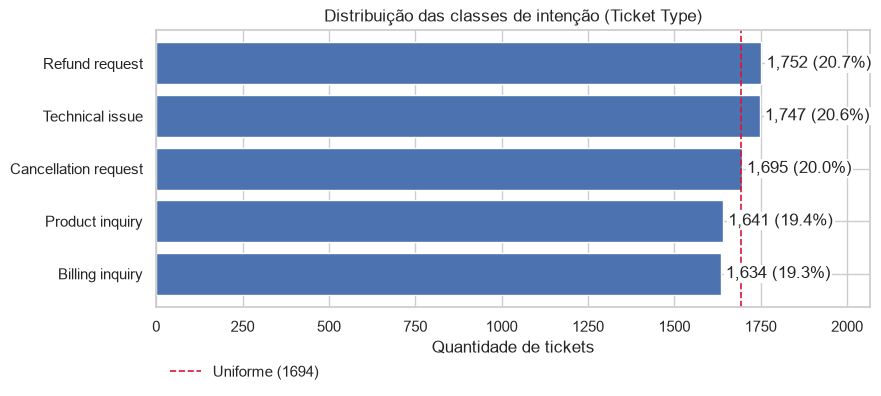

Razão maior/menor classe: 1.072
Qui-quadrado de aderência à distribuição uniforme: chi2=7.43, gl=4, p=0.1149


In [22]:
API_LABELS = {
    'Billing inquiry': 'billing_inquiry',
    'Cancellation request': 'cancellation_request',
    'Product inquiry': 'product_inquiry',
    'Refund request': 'refund_request',
    'Technical issue': 'technical_issue',
}

class_counts = df['Ticket Type'].value_counts()
class_dist = pd.DataFrame({
    'Rótulo na API (y)': class_counts.index.map(API_LABELS),
    'Quantidade': class_counts,
    'Percentual (%)': (class_counts / class_counts.sum() * 100).round(2),
})
class_dist.loc['Total'] = ['—', class_counts.sum(), 100.0]
display(class_dist)

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(class_counts.index[::-1], class_counts.values[::-1], color=sns.color_palette()[0])
ax.axvline(class_counts.mean(), color='crimson', ls='--', lw=1.2,
           label=f'Uniforme ({class_counts.mean():.0f})')
for bar, value in zip(bars, class_counts.values[::-1]):
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height() / 2,
            f'{value:,} ({value / class_counts.sum():.1%})', va='center',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.set(title='Distribuição das classes de intenção (Ticket Type)',
       xlabel='Quantidade de tickets', xlim=(0, class_counts.max() * 1.18))
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.16), frameon=False)
plt.tight_layout()
plt.show()

chi2, chi_p = stats.chisquare(class_counts.values)
print(f'Razão maior/menor classe: {class_counts.max() / class_counts.min():.3f}')
print(f'Qui-quadrado de aderência à distribuição uniforme: chi2={chi2:.2f}, '
      f'gl={len(class_counts) - 1}, p={chi_p:.4f}')

**Leitura da distribuição:**

- O modelo deverá prever **5 classes**: `billing_inquiry`, `cancellation_request`, `product_inquiry`, `refund_request` e `technical_issue` (os mesmos valores do enum `Intent` em `fastapi/domain/prediction.py`).
- A maior classe (`Refund request`, 20,69%) e a menor (`Billing inquiry`, 19,29%) diferem em apenas **1,4 ponto percentual**, e a razão entre elas é **1,07**.
- O teste qui-quadrado de aderência à distribuição uniforme **não rejeita** a hipótese de classes igualmente frequentes (χ² = 7,43; gl = 4; **p = 0,115**). **Não existem classes significativamente mais frequentes que outras.**

**Consequências para a modelagem:**

- Não é necessário reamostrar (*oversampling* / *undersampling*) nem usar `class_weight`.
- A acurácia não fica inflada por uma classe dominante, mas o **macro-F1** continua sendo a métrica principal, por dar o mesmo peso às cinco intenções.
- O piso de referência é claro: um classificador que chuta ao acaso, respeitando as proporções, acerta ~20%. Qualquer modelo útil precisa ficar **claramente acima de 0,20** de macro-F1.
- A divisão treino/teste deve ser **estratificada** por `Ticket Type`, para preservar essas proporções nos dois conjuntos.


### 3.3. Por que classificação, e não regressão linear

1. **O alvo é nominal.** `Ticket Type` é uma categoria sem ordem e sem distância. Não existe "Refund request" maior que "Billing inquiry", nem uma intenção que fique "no meio" de outras duas. A regressão linear prevê um número contínuo, então exigiria transformar as classes em 0, 1, 2, 3, 4. Esse número é arbitrário e inventa uma ordem e distâncias que o problema não tem.
2. **O resultado dependeria da codificação escolhida.** Como o modelo minimiza o erro quadrático entre números, trocar quais números representam quais classes muda o modelo e as previsões, embora o problema continue o mesmo. Um classificador é invariante a isso.
3. **A saída não é uma intenção.** A regressão devolve valores como 2,37 ou −0,8. Eles precisam ser arredondados e cortados para virar classes, e esse pós-processamento favorece as classes de "código do meio".
4. **Não há probabilidade por classe.** A API precisa de `intent` e `confidence`. Modelos de classificação (Regressão Logística, Naive Bayes, SVM com calibração) devolvem uma distribuição de probabilidade sobre as 5 classes. A regressão linear não.
5. **A métrica certa é de classificação.** O que importa é acertar a classe (acurácia, precisão, recall, macro-F1, matriz de confusão), não errar "por pouco" em uma escala numérica. RMSE e R² não têm significado para intenções.

A célula abaixo demonstra os itens 2 e 3 com os dados do projeto: o **mesmo** texto e a **mesma** divisão treino/teste, mudando apenas os números atribuídos às classes.


In [23]:
# Demonstração: tratar as intenções como números e usar regressão linear.
# Mesmo texto, mesma divisão treino/teste; muda apenas o número atribuído a cada classe.
y_cls = df['Ticket Type']
Xt_train, Xt_test, yc_train, yc_test = train_test_split(
    df['Ticket Description'], y_cls, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_cls,
)
classes = sorted(y_cls.unique())
encodings = {
    'Codificação 1 (alfabética)': {c: i for i, c in enumerate(classes)},
    'Codificação 2 (permutada)': {c: i for i, c in enumerate(
        ['Refund request', 'Billing inquiry', 'Technical issue',
         'Product inquiry', 'Cancellation request'])},
}

rows = []
for name, enc in encodings.items():
    decode = {v: k for k, v in enc.items()}
    reg_text = make_pipeline(CountVectorizer(), LinearRegression())
    reg_text.fit(Xt_train, yc_train.map(enc))
    raw = reg_text.predict(Xt_test)
    labels = pd.Series(np.clip(np.rint(raw), 0, 4).astype(int)).map(decode)
    rows.append({
        'Abordagem': f'Regressão linear — {name}',
        'Previsões fora de [0, 4] (%)': ((raw < 0) | (raw > 4)).mean() * 100,
        'Previsões não inteiras (%)': (np.abs(raw - np.rint(raw)) > 0.05).mean() * 100,
        'Acurácia': accuracy_score(yc_test, labels),
        'Macro-F1': f1_score(yc_test, labels, average='macro'),
    })

for name, clf in {
    'Classificador aleatório estratificado': DummyClassifier(strategy='stratified',
                                                             random_state=RANDOM_STATE),
    'CountVectorizer + Regressão Logística': make_pipeline(
        CountVectorizer(), LogisticRegression(max_iter=3000)),
}.items():
    clf.fit(Xt_train, yc_train)
    pred = clf.predict(Xt_test)
    rows.append({'Abordagem': name, 'Previsões fora de [0, 4] (%)': 0.0,
                 'Previsões não inteiras (%)': 0.0,
                 'Acurácia': accuracy_score(yc_test, pred),
                 'Macro-F1': f1_score(yc_test, pred, average='macro')})

display(pd.DataFrame(rows).set_index('Abordagem').round(3))

,"Previsões fora de [0, 4] (%)",Previsões não inteiras (%),Acurácia,Macro-F1
Abordagem,,,,
Regressão linear — Codificação 1 (alfabética),26.623,91.086,0.204,0.199
Regressão linear — Codificação 2 (permutada),26.741,87.190,0.194,0.189
Classificador aleatório estratificado,0.000,0.000,0.187,0.186
CountVectorizer + Regressão Logística,0.000,0.000,0.198,0.197


**O que a demonstração mostra:**

- **Cerca de 27%** das previsões da regressão linear caem **fora do intervalo [0, 4]**, ou seja, não correspondem a nenhuma classe. Entre **87% e 91%** não são números inteiros. Em ambos os casos, foi preciso arredondar e cortar o valor para obter uma intenção.
- Trocar apenas **quais números representam quais classes** mudou a acurácia (0,204 → 0,194) e o macro-F1 (0,199 → 0,189), embora o texto, os dados e o problema fossem os mesmos. O resultado depende de uma escolha arbitrária, o que confirma que a regressão impõe uma ordem que não existe.
- A Regressão Logística devolve diretamente uma das 5 classes, com a probabilidade de cada uma, e não depende de codificação.

**Atenção:** as quatro abordagens ficaram com acurácia e macro-F1 em torno de **0,19–0,20**, igual ao classificador aleatório. A superioridade da classificação, portanto, é **conceitual** (saída válida, invariância à codificação, probabilidades), e não de desempenho neste dataset. A próxima célula investiga por quê.


In [24]:
# Verificação de viabilidade para o TP4: há sinal no texto que separe as intenções?
# Validação cruzada estratificada (5 folds) com a representação definida no planejamento.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    'Aleatório estratificado (piso)': DummyClassifier(strategy='stratified',
                                                      random_state=RANDOM_STATE),
    'CountVectorizer + Regressão Logística': make_pipeline(
        CountVectorizer(), LogisticRegression(max_iter=3000)),
    'CountVectorizer (1-2 gramas) + Regressão Logística': make_pipeline(
        CountVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(max_iter=3000)),
}
viab = pd.DataFrame({
    name: cross_val_score(model, df['Ticket Description'], y_cls, cv=cv5, scoring='f1_macro')
    for name, model in candidates.items()
}).agg(['mean', 'std']).T.rename(columns={'mean': 'Macro-F1 médio', 'std': 'Desvio'})
display(viab.round(3))

# O mesmo teste para o assunto do ticket: se nem o assunto separa as intenções,
# o problema está na relação rótulo × texto, não no algoritmo.
subject_vs_type = pd.crosstab(df['Ticket Subject'], df['Ticket Type'], normalize='index') * 100
print('Maior concentração de um Ticket Type dentro de um mesmo Ticket Subject: '
      f'{subject_vs_type.max(axis=1).max():.1f}% (uniforme = 20%)')
chi2_s, p_s, dof_s, _ = stats.chi2_contingency(pd.crosstab(df['Ticket Subject'],
                                                           df['Ticket Type']))
print(f'Qui-quadrado de independência Subject × Type: chi2={chi2_s:.1f}, gl={dof_s}, '
      f'p={p_s:.4f}')

,Macro-F1 médio,Desvio
Aleatório estratificado (piso),0.205,0.016
CountVectorizer + Regressão Logística,0.194,0.012
CountVectorizer (1-2 gramas) + Regressão Logística,0.193,0.014


Maior concentração de um Ticket Type dentro de um mesmo Ticket Subject: 23.6% (uniforme = 20%)
Qui-quadrado de independência Subject × Type: chi2=39.6, gl=60, p=0.9807


### 3.5. Verificação de viabilidade: existe sinal no texto?

Antes de planejar o TP4, foi feito um teste com validação cruzada estratificada de 5 folds, usando exatamente a representação definida no planejamento (CountVectorizer):

- **CountVectorizer + Regressão Logística** obteve macro-F1 de **0,194 ± 0,012**, e a versão com unigramas e bigramas, **0,193 ± 0,014**. O **classificador aleatório** obteve **0,205 ± 0,016**. Os modelos **não superam o acaso**.
- O problema não está no algoritmo. Mesmo `Ticket Subject`, que nomeia o assunto do ticket (por exemplo "Refund request"), é **independente** de `Ticket Type`: o qui-quadrado de independência dá p = 0,98, e nenhum assunto concentra mais de 23,6% de um mesmo tipo, contra 20% esperados ao acaso.
- A inspeção da seção 1.5 já tinha mostrado o motivo: as descrições são **templates sintéticos** (`I'm having an issue with the {product_purchased}. Please assist.` + frases sorteadas), e o placeholder `{product_purchased}` nem foi substituído. **O rótulo `Ticket Type` foi atribuído de forma independente do texto.**

**Implicação para o projeto:** a formalização da seção 3.1 está correta como problema, já que é exatamente o que a API precisa resolver. Porém, **este dataset não contém sinal que permita aprender X → y**. Qualquer classificador treinado só com ele vai ficar perto de 20% de macro-F1. Esse é o principal risco técnico do TP4, e as alternativas estão registradas em `others/planejamento_tp3.md`: manter o dataset e documentar o piso, rotular manualmente uma amostra pelo conteúdo do texto, ou complementar com um dataset de intenções com texto real.


## 4. Conclusões do TP3

| Pergunta | Resposta |
| --- | --- |
| O tamanho das mensagens pode ser previsto por regressão linear? | Pouco. Os metadados não explicam nada (R² ≈ −0,01) e a estrutura do texto explica ~12% (R² 0,123; RMSE 7,9 palavras). Os resíduos são assimétricos, heterocedásticos e não normais. |
| O que o modelo de ML deve responder? | A intenção (`Ticket Type`, 5 classes) a partir do texto (`Ticket Description`). |
| As classes estão balanceadas? | Sim. Variam de 19,3% a 20,7%, e o qui-quadrado não rejeita a uniformidade (p = 0,115). |
| Por que classificação? | O alvo é nominal. A regressão inventa ordem e distâncias, gera saídas inválidas (27% fora de [0, 4]) e depende da codificação. |
| O dataset permite aprender a intenção? | **Não, no estado atual.** CountVectorizer + Regressão Logística fica no nível do acaso (macro-F1 ≈ 0,19), porque o rótulo é independente do texto. |

**Próximos passos (TP4):** treinar o classificador planejado em `others/planejamento_tp3.md` (CountVectorizer + Regressão Logística, com SVM linear como comparação) com divisão estratificada. Os resultados serão reportados contra o piso de 0,20 de macro-F1, e a equipe decide qual estratégia adotar para o risco identificado na seção 3.5.
